In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt
import numpy as np
import os

In [7]:
# Use GPU if it is available. Otherwise use CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [8]:
# Connect Google Drive with Google Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
# Install a tool to extract the RAR file
!apt-get -qq install -y unrar

In [10]:
# Give the location of the RAR file
rar_path = '/content/drive/MyDrive/Mango_CNN/Mango Leaf Origianl.rar'

# This is where the images will be extracted
extract_path = '/content/mango_leaf_data'

# Extract the RAR file
!mkdir -p /content/mango_leaf_data
!unrar x -o- "{rar_path}" "{extract_path}/"


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/drive/MyDrive/Mango_CNN/Mango Leaf Origianl.rar

Creating    /content/mango_leaf_data/Mango Leaf Origianl              OK
Creating    /content/mango_leaf_data/Mango Leaf Origianl/Anthracnose  OK
Extracting  /content/mango_leaf_data/Mango Leaf Origianl/Anthracnose/Anthracnose_10.jpg       0%  OK 
Extracting  /content/mango_leaf_data/Mango Leaf Origianl/Anthracnose/Anthracnose_100.jpg       0%  OK 
Extracting  /content/mango_leaf_data/Mango Leaf Origianl/Anthracnose/Anthracnose_101.jpg       0%  OK 
Extracting  /content/mango_leaf_data/Mango Leaf Origianl/Anthracnose/Anthracnose_102.jpg       0%  OK 
Extracting  /content/mango_leaf_data/Mango Leaf Origianl/Anthracnose/Anthracnose_103.jpg       0%  OK 
Extracting  /content/mango_leaf_data/Mango Leaf Origianl/Anthracnose/Anthracnose_104.jpg       0%  OK 
Extracting  /content/mango_leaf_data/Man

In [11]:
# Find folders that contain image-class folders
from pathlib import Path

image_extensions = ['.jpg', '.jpeg', '.png', '.bmp']

possible_folders = []

for root, dirs, files in os.walk(extract_path):
    class_folders = []

    for folder in dirs:
        folder_path = Path(root) / folder

        # Check whether this folder contains image files
        image_files = []
        for ext in image_extensions:
            image_files.extend(list(folder_path.rglob('*' + ext)))

        if len(image_files) > 0:
            class_folders.append(folder)

    if len(class_folders) >= 2:
        possible_folders.append((root, class_folders))

for folder, classes in possible_folders:
    print('Dataset folder:', folder)
    print('Classes:', classes)
    print()

Dataset folder: /content/mango_leaf_data/Mango Leaf Origianl
Classes: ['Powdery Mildew', 'Healthy', 'Anthracnose', 'Gall Midge']



In [12]:
if len(possible_folders) == 0:
    print('No class folders found. Please check the extracted folder structure.')
else:
    data_path = max(possible_folders, key=lambda item: len(item[1]))[0]
    print('Selected dataset folder:', data_path)

Selected dataset folder: /content/mango_leaf_data/Mango Leaf Origianl


In [13]:
# Image size and batch size
img_size = 64
batch_size = 32

# Resize images and convert them to tensors
transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor()
])

# Load all images from the class folders
all_data = datasets.ImageFolder(data_path, transform=transform)

# Show class names and total images
class_names = all_data.classes
num_classes = len(class_names)

print('Classes:', class_names)
print('Number of classes:', num_classes)
print('Total images:', len(all_data))

Classes: ['Anthracnose', 'Gall Midge', 'Healthy', 'Powdery Mildew']
Number of classes: 4
Total images: 2000


In [14]:
# Calculate the number of images for each part
total_size = len(all_data)

train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

# Split the dataset
train_ds, val_ds, test_ds = random_split(
    all_data,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print('Training images:', len(train_ds))
print('Validation images:', len(val_ds))
print('Testing images:', len(test_ds))

Training images: 1400
Validation images: 300
Testing images: 300


In [15]:
# DataLoader sends images to the model in small batches
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_dl = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

In [16]:
# CNN Model
class MangoCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        # First convolution block
        self.conv1 = nn.Conv2d(3, 8, kernel_size=3, padding=1)

        # Second convolution block
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)

        # Max pooling layer
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layer
        # 16 feature maps × 16 × 16 image size
        self.fc = nn.Linear(16 * 16 * 16, num_classes)

    def forward(self, x):

        # First convolution
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)

        # Second convolution
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)

        # Flatten the feature maps
        x = torch.flatten(x, 1)

        # Final class scores
        x = self.fc(x)

        return x


# Create the model
model = MangoCNN(num_classes).to(device)

print(model)

MangoCNN(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=4096, out_features=4, bias=True)
)


In [17]:
# Loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Number of training rounds
epochs = 10

# Save loss and accuracy values for graphs
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

In [18]:
for ep in range(epochs):

    # ---------------- TRAINING ----------------
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for img, label in train_dl:

        img = img.to(device)
        label = label.to(device)

        optimizer.zero_grad()

        output = model(img)
        loss = loss_fn(output, label)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        prediction = torch.argmax(output, dim=1)
        correct += (prediction == label).sum().item()
        total += label.size(0)

    train_loss = total_loss / len(train_dl)
    train_acc = correct / total

    # ---------------- VALIDATION ----------------
    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for img, label in val_dl:

            img = img.to(device)
            label = label.to(device)

            output = model(img)
            loss = loss_fn(output, label)

            val_loss += loss.item()

            prediction = torch.argmax(output, dim=1)
            val_correct += (prediction == label).sum().item()
            val_total += label.size(0)

    val_loss = val_loss / len(val_dl)
    val_acc = val_correct / val_total

    # Save values
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print('Epoch:', ep + 1)
    print('Train Loss:', round(train_loss, 4))
    print('Train Accuracy:', round(train_acc, 4))
    print('Validation Loss:', round(val_loss, 4))
    print('Validation Accuracy:', round(val_acc, 4))
    print('-------------------------------')

Epoch: 1
Train Loss: 1.2713
Train Accuracy: 0.4129
Validation Loss: 1.0455
Validation Accuracy: 0.6433
-------------------------------
Epoch: 2
Train Loss: 0.919
Train Accuracy: 0.6371
Validation Loss: 0.8172
Validation Accuracy: 0.6867
-------------------------------
Epoch: 3
Train Loss: 0.7375
Train Accuracy: 0.7171
Validation Loss: 0.8066
Validation Accuracy: 0.6467
-------------------------------
Epoch: 4
Train Loss: 0.6568
Train Accuracy: 0.7486
Validation Loss: 0.6051
Validation Accuracy: 0.7467
-------------------------------
Epoch: 5
Train Loss: 0.5648
Train Accuracy: 0.78
Validation Loss: 0.5667
Validation Accuracy: 0.7867
-------------------------------
Epoch: 6
Train Loss: 0.5018
Train Accuracy: 0.82
Validation Loss: 0.545
Validation Accuracy: 0.7767
-------------------------------
Epoch: 7
Train Loss: 0.4739
Train Accuracy: 0.8257
Validation Loss: 0.6242
Validation Accuracy: 0.73
-------------------------------
Epoch: 8
Train Loss: 0.4811
Train Accuracy: 0.8179
Validation L

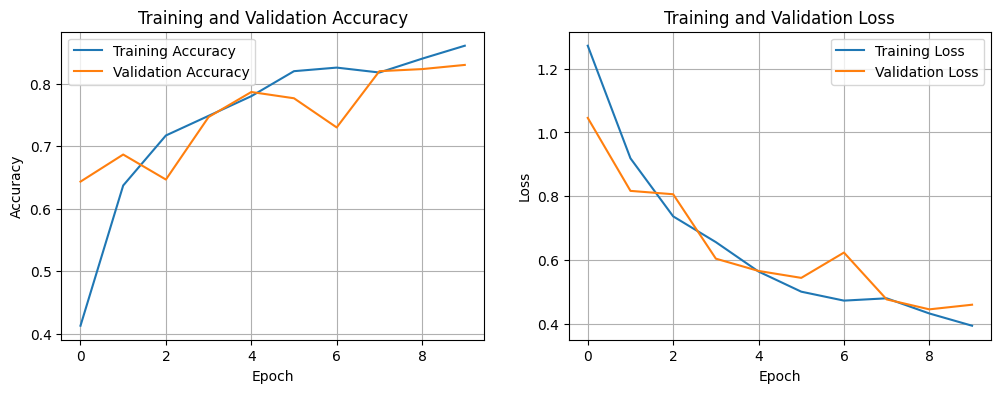

In [19]:
plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

In [20]:
model.eval()

test_correct = 0
test_total = 0
test_loss = 0

with torch.no_grad():
    for img, label in test_dl:

        img = img.to(device)
        label = label.to(device)

        output = model(img)
        loss = loss_fn(output, label)

        test_loss += loss.item()

        prediction = torch.argmax(output, dim=1)
        test_correct += (prediction == label).sum().item()
        test_total += label.size(0)

test_accuracy = test_correct / test_total
test_loss = test_loss / len(test_dl)

print('Test Loss:', round(test_loss, 4))
print('Test Accuracy:', round(test_accuracy, 4))
print('Test Accuracy (%):', round(test_accuracy * 100, 2))

Test Loss: 0.5606
Test Accuracy: 0.8333
Test Accuracy (%): 83.33


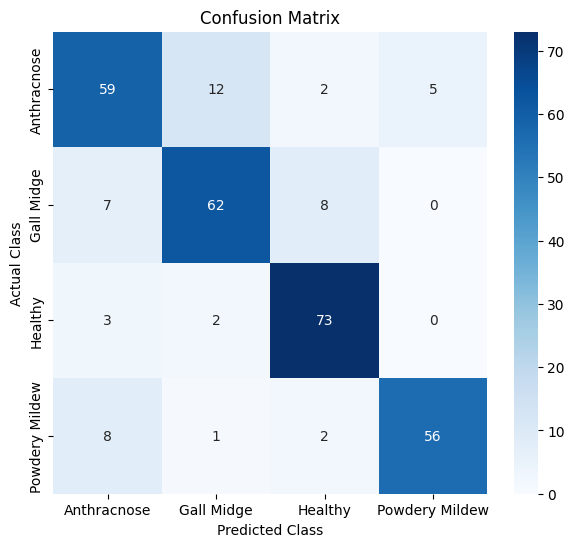

                precision    recall  f1-score   support

   Anthracnose       0.77      0.76      0.76        78
    Gall Midge       0.81      0.81      0.81        77
       Healthy       0.86      0.94      0.90        78
Powdery Mildew       0.92      0.84      0.88        67

      accuracy                           0.83       300
     macro avg       0.84      0.83      0.83       300
  weighted avg       0.83      0.83      0.83       300



In [21]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

all_preds = []
all_labels = []

model.eval()

with torch.no_grad():
    for img, label in test_dl:

        img = img.to(device)

        output = model(img)
        prediction = torch.argmax(output, dim=1)

        all_preds.extend(prediction.cpu().numpy())
        all_labels.extend(label.numpy())

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    zero_division=0
))

In [22]:
torch.save(model.state_dict(), 'mango_leaf_cnn.pth')
print('Model saved successfully.')

Model saved successfully.
